# HW2 — Evapotranspiration and FAO-56


## FAO-56 Reference Evapotranspiration


### Net Solar Radiation


#### Extraterrestrial Radiation


In [1]:
# import libraries
import numpy as np
pi = np.pi

In [2]:
#### Calculating extraterrestrial radiation (Ra)

# solar constant [MJ/(m^2*min)]
G_sc = 0.0820

# relative Earth-Sun distance (Equation 23) and solar declination angle (Equation 24) are both based on day of year
# day of year:
J = 275 #day after Jan 1 [0,365]


# inverse relative Earth-Sun distance [unitless] (Equation 23)
d_r = 1 + 0.033*np.cos(2*pi*J/365)

# solar declination angle [rad] (Equation 24)
delta = 0.409*np.sin(2*pi*J/365 - 1.39)

# sunset angle (Equation 25) is dependent on latitude [rad]
# latitude:
phi = pi/6 #radians where positive means north of the equator [-pi/2,pi/2]
# python's default units for angles is radians!

# sunset hour angle [rad] (Equation 25)
omega_s = np.arccos(-np.tan(phi)*np.tan(delta))

#Now we can calculate Extraterrestial Radiation: Ra [MJ/(m^2*min)]
R_a = (24*60/pi)*G_sc*d_r*(omega_s*np.sin(phi)*np.sin(delta) + np.cos(phi)*np.cos(delta)*np.sin(omega_s))
print(f'The extraterrestrial solar radiation R_a is {R_a:.3f} MJ/(m^2*day)')

The extraterrestrial solar radiation R_a is 30.075 MJ/(m^2*day)


#### Incoming Solar Radiation


In [3]:
#### Calculating incoming solar radiation (Rs)

# maximum daylight hours based on location [hr] (Equation 34)
N = 24*omega_s/pi 

# actual duration of sunshine [hr]
# this parameter is essentially based on how much of the day is cloudy vs sunny
n = 10 #[0,N]
# this parameter must be less than N
if n > N:
    print("Error: actual hours of sunshine (n) cannot be greater than maximum sunlight hours (N)")

# recommended Angstrom constants when no actual solar radiation data are available
# here, no calibration has been carried out for improved as and bs parameters (SEE FAO-56 for more info)
a_s = 0.25
b_s = 0.55

# calculate incoming solar radiation at the ground (Equation 35)
R_s = (a_s+b_s*(n/N))*R_a
print(f'The amount of solar radiation R_s that hit the ground is {R_s:.3f} MJ/(m^2*day)')

#Clear-sky radiation (Rso) occurs when n/N = 1
R_so = (a_s+b_s)*R_a
print(f'Maximum solar radiation R_so at the ground is {R_so:.3f} MJ/(m^2*day)')

The amount of solar radiation R_s that hit the ground is 21.734 MJ/(m^2*day)
Maximum solar radiation R_so at the ground is 24.060 MJ/(m^2*day)


#### Net Shortwave Radiation


In [4]:
#### Calculating net shortwave radiation (R_ns)

# set albedo (usually around 0.3 but landcover-dependent)
albedo = 0.3 #[0,1]

# calculate net solar shortwave radiation (Equation 38)
R_ns = R_s*(1-albedo)
print(f'Net shortwave radiation is {R_ns:.3f} MJ/(m^2*day)')

Net shortwave radiation is 15.214 MJ/(m^2*day)


#### Net Longwave Radiation


In [5]:
#Starting with known values

# Stefan-Boltzmann constant [MJ/(K^4*m^2)]
sigma = 4.903E-9

# set T_max and T_min [C]
# hopefully we'd have real data for this(try experimenting with these parameters)
T_min = 15
T_max = 25
# we will also need T_mean for later; assume the average of the minimum and maximum temperatures is the average temperature for the whole day
T_mean = T_min + T_max

#### Vapor Pressure from Dewpoint Temperature


In [6]:
# set dewpoint offset, should be between 0 and 2
K_0 = 2
T_dew = T_min - K_0

# calculate actual vapor pressure from dewpoint [kPa] - see Equation (14) in FAO-56
e_a = 0.6108*np.exp((17.27*T_dew)/(T_dew + 237.3))
print(f'The actual vapor pressure is {e_a:.2f} kPa')

The actual vapor pressure is 1.50 kPa


#### Net Longwave Radiation Calculation


In [7]:
###### calculate net longwave up - see Equation (39) in FAO-56
R_nl = sigma*(((T_min + 273.16)**4 + (T_max + 273.16)**4)/2)*(0.34-0.14*np.sqrt(e_a))*(1.35*(R_s/R_so) -0.35)
# note that temperature units were converted to kelvin

print(f'The net longwave radiation up is {R_nl:.2f} MJ/(m^2*day)')

The net longwave radiation up is 5.32 MJ/(m^2*day)


#### Net Radiation


In [8]:
# calculate net radiation - radiation in minus radiation out - see Equation (40) in FAO-56
R_n = R_ns - R_nl
# this R_n energy drives ET
print(f'The net radiation at the surface is {R_n:.2f} MJ/(m^2*day)')

The net radiation at the surface is 9.89 MJ/(m^2*day)


### Vapor Pressure


In [9]:
# define a function
def calc_e_0(T):
    
    # this function calculates saturation vapor pressure
    # temperature input must be given in Celsius
    
    # calculate the saturation vapor pressure - see Equation (11) in FAO-56
    e_0 = 0.6108*np.exp((17.27*T)/(T + 237.3))
    
    # return the value
    return e_0

# calculate mean saturation vapor pressure [kPa] from the min and max saturation vapor pressures
e_s = (calc_e_0(T_max) + calc_e_0(T_min))/2

print(f'The mean saturation vapor pressure is {e_s:.2f} kPa')
print(f'The vapor pressure deficit is {e_s-e_a:.2f} kPa')

The mean saturation vapor pressure is 2.44 kPa
The vapor pressure deficit is 0.94 kPa


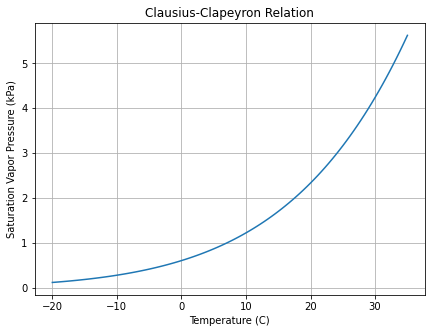

In [10]:
# import matplotlib
import matplotlib.pyplot as plt

# first, get a 1-D array of temperatures in celsius
# the linspace function returns this array between 
T_array = np.linspace(-20,35,100)

# plot
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(T_array,calc_e_0(T_array))
ax.set_xlabel('Temperature (C)')
ax.set_ylabel('Saturation Vapor Pressure (kPa)')
ax.set_title('Clausius-Clapeyron Relation')
ax.grid()

### Slope of the Saturation Vapor Pressure Curve


In [11]:
# define a function to calculate
def calc_delta(T):
    
    # this function calculates the slope of the vapor pressure curve at a given temperature
    # temperature must be given in Celsius
    
    # calculate the slope
    delta = 4096*(0.6108*np.exp(17.27*T/(T+237.3)))/(T + 237.3)**2
    
    # return the value
    return delta

delta = calc_delta(T_mean)

print(f'The slope of the saturation vapor pressure is {delta:.2f} kPa/C')

The slope of the saturation vapor pressure is 0.39 kPa/C


### Psychrometric Constant


In [12]:
# specific heat capacity of air [MJ/(kg*K)]
c_a = 10e-3

# atmospheric pressure [kPa]
p = 101.3

# latent heat of vaporization [MJ/kg]
lv = 2.47

# ratio of the molecular weight of water vapor to dry air
epsilon = 0.622

# calculate psychometric constant
gamma = c_a*p/(epsilon*lv)
print(f'The psychometric constant is {gamma:.3f} kPa/K (also kPa/C)')

The psychometric constant is 0.659 kPa/K (also kPa/C)


### Wind Speed at 2 m


In [13]:
# set the wind speed [m/s] at some height [m] other than 2m
# (try experimenting with these values)

# height you measured wind at (m)
z = 2

# windspeed at that height (m/s)
u_z = 3.5

# calculate the wind speed at 2 meters
# could define a function again, but sometimes easier just to write it out
u_2 = u_z*4.87/np.log(67.8*z-5.42)
print(f'The wind speed 2 meters above ground is {u_2:.3f} m/s')

The wind speed 2 meters above ground is 3.501 m/s


### Reference Evapotranspiration


In [14]:
# calculate reference evapotranspiration
ET_0 = (0.408*delta*R_n+gamma*(900/(T_mean+273))*u_2*(e_s-e_a))/(delta+gamma*(1+0.34*u_2))
print(f'The reference evapotranspiration is {ET_0:.4f} mm/day')

The reference evapotranspiration is 4.2551 mm/day


## Coursework Analysis


### Q1 — Evapotranspiration and Water Balance


#### Q1.1 — Reference Evapotranspiration


In [15]:
## Q1.1
import pandas as pd
import numpy as np

# DAYMET URL
url = "https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start=2020-07-01&end=2020-08-01&format=csv"

# read in the data much like before
weather = pd.read_csv(url, skiprows=6)
weather.head()

,year,yday,dayl (s),prcp (mm/day),srad (W/m^2),swe (kg/m^2),tmax (deg c),tmin (deg c),vp (Pa)
0,2020,183,53375.69,3.02,270.03,0.0,28.44,18.06,2071.17
1,2020,184,53335.59,0.00,472.14,0.0,33.54,17.20,1952.25
2,2020,185,53292.05,12.28,313.90,0.0,33.67,20.03,2341.30
3,2020,186,53245.11,0.00,375.07,0.0,31.59,20.25,2373.97
4,2020,187,53194.80,0.00,422.31,0.0,34.43,20.40,2395.28


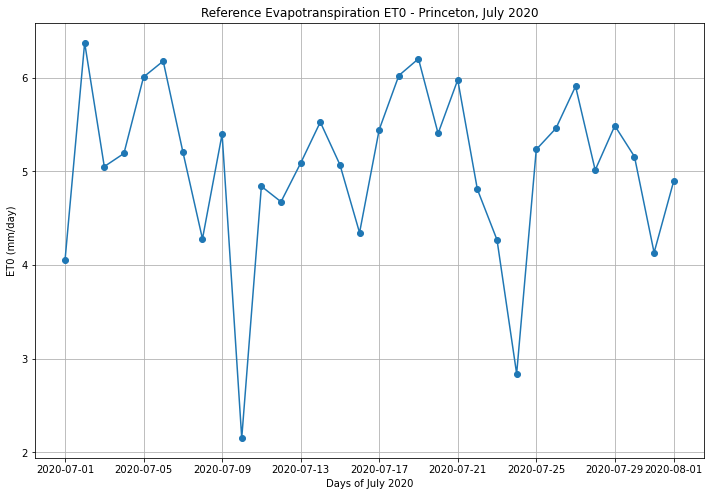

In [16]:
### your code goes below ###

#Needed variables from the dataframe
T_min = weather['tmin (deg c)']
T_max = weather['tmax (deg c)']
T_mean = (T_min + T_max)/2

#CONSTANTS
u2 = 2 #windspeed
albedo = 0.23  # reflection coefficient
sigma = 4.903e-9  # Stefan-Boltzmann constant for unite [MJ/(K^4*m^2)]
a_s = 0.25  # Angstrom constant
b_s = 0.55  # Angstrom constant
gamma = 0.066  # psychrometric constant
G = 0  # soil heat flux 


#Finding R_a that changes daily a bit. So, I thought using one R_a value would be inaccurate.

J = pd.to_datetime(weather['year']*1000 + weather['yday'], format='%Y%j').dt.dayofyear #accounting for daily chage in day etc
phi = np.deg2rad(40.3573)  # Princeton latitude in radians
pi = np.pi
G_sc = 0.0820  # MJ/m²/min
d_r = 1 + 0.033*np.cos(2*pi*J/365)
deltaS = 0.409 * np.sin(2*pi*J/365 - 1.39)
omega_s = np.arccos(-np.tan(phi)*np.tan(delta))
R_a = (24*60/pi) * G_sc * d_r * (omega_s*np.sin(phi)*np.sin(deltaS) + np.cos(phi)*np.cos(deltaS)*np.sin(omega_s))




R_s = weather['srad (W/m^2)'] * weather['dayl (s)'] / 1e6  #converting intensity into intensity per day MJ/m²/day
R_so = (a_s + b_s) * R_a  # clear-sky radiation 
R_ns = (1 - albedo) * R_s



# function to calculate saturation vapor pressure
def calc_e0(T):
    return 0.6108 * np.exp((17.27*T)/(T+237.3))

# actual vapor pressure #here finding T dewpoint assuming 2 as stated in the example
e_a = calc_e0(T_min - 2)

R_nl = sigma * (((T_max+273.16)**4 + (T_min+273.16)**4)/2) * (0.34 - 0.14*np.sqrt(e_a)) * (1.35*(R_s/R_so) - 0.35)
R_n = R_ns - R_nl

# mean saturation vapor pressure
e_s = (calc_e0(T_max) + calc_e0(T_min))/2



delta = 4096 * e_s / (T_mean + 237.3)**2


ET0 = (0.408*delta*(R_n) + gamma*(900/(T_mean + 273))*u2*(e_s - e_a)) / (delta + gamma*(1 + 0.34*u2))

dates = pd.to_datetime(weather['year'].astype(str) + '-' + 
                       weather['yday'].astype(str), format='%Y-%j')


plt.figure(figsize=(12,8))
plt.plot(dates, ET0, marker='o')
plt.xlabel('Days of July 2020')
plt.ylabel('ET0 (mm/day)')
plt.title('Reference Evapotranspiration ET0 - Princeton, July 2020')
plt.grid()
plt.show()


In [17]:
# Q1.2
url = 'https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites=01401000&startDT=2020-07-01&endDT=2020-08-01&siteStatus=all'
StonyBrook_July = pd.read_csv(url, sep='\t', skiprows=32)
StonyBrook_July = StonyBrook_July.drop(StonyBrook_July.columns[[3,4,5,6,7,8]], axis=1)
StonyBrook_July.columns = ['agency','site','datetime','Flow_cfs','id']
StonyBrook_July['datetime'] = pd.to_datetime(StonyBrook_July['datetime'])

### your code below here ###

area_m2 = 44.5 * 2.59e6  #converting from miles squared into meters squared
StonyBrook_July['Runoff_mm'] = StonyBrook_July['Flow_cfs'] * 0.0283168 * 86400 / area_m2 * 1000

# dataframe has different number of rows, so i used merge method
weather['date'] = pd.to_datetime(weather['year'].astype(str) + '-' + weather['yday'].astype(str), format='%Y-%j')

# Merging DAYMET and USGS on actual dates 
df_runoff = pd.merge(weather, StonyBrook_July, left_on='date', right_on='datetime', how='inner')

# Daily runoff ratio
df_runoff['Runoff_ratio'] = df_runoff['Runoff_mm'] / df_runoff['prcp (mm/day)']

# Results
df_display = df_runoff[['date','prcp (mm/day)','Runoff_mm','Runoff_ratio']]
print(df_display)

         date  prcp (mm/day)  Runoff_mm  Runoff_ratio
0  2020-07-01           3.02   0.091278      0.030225
1  2020-07-02           0.00   0.073659           inf
2  2020-07-03          12.28   0.469127      0.038203
3  2020-07-04           0.00   0.343885           inf
4  2020-07-05           0.00   0.104227           inf
5  2020-07-06           0.00   0.080877           inf
6  2020-07-07           1.13   0.064107      0.056732
7  2020-07-08           3.58   0.062833      0.017551
8  2020-07-09           0.00   0.098495           inf
9  2020-07-10          71.71   5.582823      0.077853
10 2020-07-11           0.00   3.587442           inf
11 2020-07-12           6.82   0.730225      0.107071
12 2020-07-13           0.00   0.585878           inf
13 2020-07-14           0.00   0.314166           inf
14 2020-07-15           0.00   0.209303           inf
15 2020-07-16           0.00   0.165362           inf
16 2020-07-17           0.43   0.160692      0.373702
17 2020-07-18           0.00

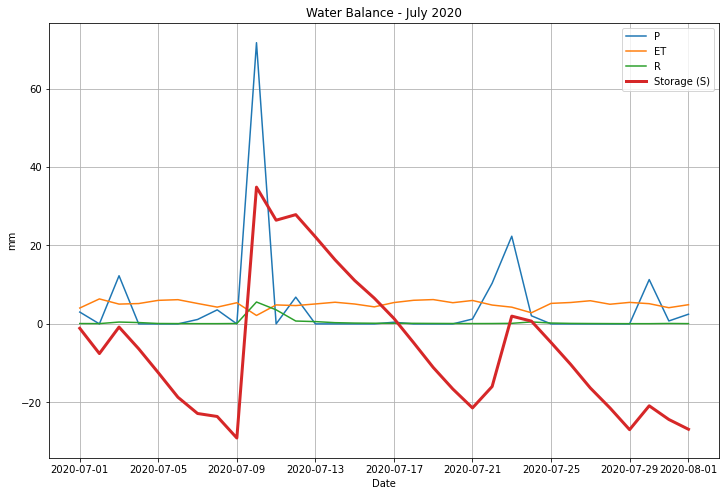

In [18]:
## Q1.3 code here


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# taking same number of days
n = min(len(weather), len(StonyBrook_July))

#variables and only considering specific n - common number days
P = weather['prcp (mm/day)'].iloc[:n].values
ET = ET0.iloc[:n].values
R = StonyBrook_July['Runoff_mm'].iloc[:n].values

# daily storage change
dS = P - ET - R

# cumulative storage (start from 0)
S = np.cumsum(dS)

# plot
dates = pd.to_datetime(weather['year'].astype(str) + '-' + weather['yday'].astype(str), format='%Y-%j')

plt.figure(figsize=(12,8))
plt.plot(dates[:n], P, label='P')
plt.plot(dates[:n], ET, label='ET')
plt.plot(dates[:n], R, label='R')
plt.plot(dates[:n], S, label='Storage (S)', linewidth=3)

plt.legend()
plt.xlabel('Date')
plt.ylabel('mm')
plt.title('Water Balance - July 2020')
plt.grid()
plt.show()

* _The water balance over July 2020 shows that storage fluctuates over time, reacting to the precipitation events. For example, it is increasing on days when precipitation (blue line) exceeds ET and runoff, and decreasing when ET and runoff are larger than precipitation. This is an expected behavior because rainfall events temporarily add water to the watershed, while dry periods cause more ET leading to loss._

* _Overall, the storage show an increase around July 10th, followed by a decrease trend generally. It is due to the fact that ET is mostly higher than precipitation, as it is July. However, this is still a simplified model and probably missing some factors. For example, we learned in class about Groundwater flow and this might be another big factor that we are not accounting in this model with ET. Other factors might be soil moisture, hydraulic conductivity, or infiltration rates._ 

### Q2 — Bowen Ratio


In [19]:
# Q2.1 code here

import pandas as pd

# i uploaded my csv to google sheets for easier use
url = "https://docs.google.com/spreadsheets/d/11jwHBWJP04zCXQwbP6uCqCdVFP24hTwMC1DaRdXkLFU/export?format=csv"

df = pd.read_csv(url)


# clean column names
df.columns = df.columns.str.strip()

# renaming to simpler names
df = df.rename(columns={
    'time (hr)': 'time',
    'temp (K)': 'temp_K',
    'q (kg kg**-1)': 'q',
    'H (W m**-2)': 'H',
    'LE (W m**-2)': 'LE'
})

df['temp_C'] = df['temp_K'] - 273.15

df.head()



,time,temp_K,q,H,LE,temp_C
0,0.00,287.658826,0.008996,31.018398,-5.094413,14.508826
1,0.25,287.756831,0.008855,-23.196635,9.567501,14.606831
2,0.50,287.456517,0.008878,-11.830495,4.646546,14.306517
3,0.75,287.286251,0.008863,-12.765485,5.565894,14.136251
4,1.00,287.217244,0.008824,-17.575611,6.937760,14.067244


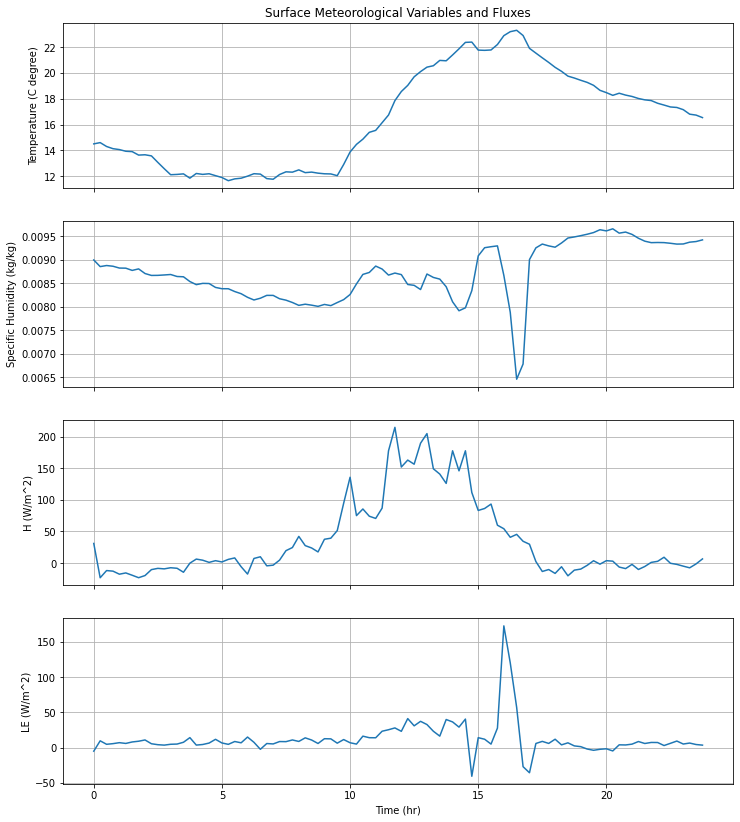

In [38]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(4, 1, figsize=(12, 14), sharex=True)

# Temperature
axs[0].plot(df['time'], df['temp_C'])
axs[0].set_ylabel("Temperature (C degree)")
axs[0].set_title("Surface Meteorological Variables and Fluxes")
axs[0].grid(True)

# Specific humidity
axs[1].plot(df['time'], df['q'])
axs[1].set_ylabel("Specific Humidity (kg/kg)")
axs[1].grid(True)

# Sensible heat flux
axs[2].plot(df['time'], df['H'])
axs[2].set_ylabel("H (W/m^2)")
axs[2].grid(True)

# Latent heat flux
axs[3].plot(df['time'], df['LE'])
axs[3].set_ylabel("LE (W/m^2)")
axs[3].set_xlabel("Time (hr)")
axs[3].grid(True)

plt.show()

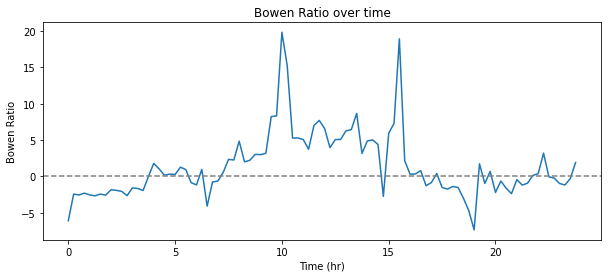

In [42]:
# Q2.2 code here


df['Bo'] = df['H'] / df['LE'].replace(0, pd.NA)

plt.figure(figsize=(10,4))
plt.plot(df['time'], df['Bo'])
plt.ylabel("Bowen Ratio")
plt.xlabel("Time (hr)")
plt.title("Bowen Ratio over time")
plt.axhline(0, linestyle='--', color='gray')  # to see sign changes clearly
plt.show()

* _The ratio graph can be analyzed looking at separate 4 graphs of different variables. Negative values are caused when the signs of H and LE differ. Ratio is usually negative when it is a night time, because surface cools after sunset, causing sensible heat exchange (H) to go into negative, while LE stays a bit above zero. Regarding two spikes: The first large spike occurs at around 10 AM when solar radiation on E-QUAD increases rapidly, causing the sensible heat exchange to rise relatively sharply while evaporation lags behind. This increases the H value, causing ratio to go to positive. Around midday, evaporation increases gradually as more energy is used for phase change, leading to higher latent heat flux. So, Bowen ratio decreases a bit during the midday. The second peak occurs in the afternoon after about 3 PM as the temperature reaches one of the highest points of the day. It is followed by increase in LE. As LE increases, a larger fraction of  energy is used for evaporation rather than sensible heating, causing ratio to have a larger decrease. After this event, both H and LE start stabilizing until the next morning._ 

In [43]:
# Q2.3 code here

Bo_avg = df['Bo'].mean()
print("Average Bowen ratio:", Bo_avg)

Average Bowen ratio: 1.418751647149957


* _Value of 1.4 is significantly higher than a suggest 0.4 to 0.8. So, sensible heat flux dominates over latent heat flux. More energy is going into heating the air, instead of evaporating. This indicates, or rather proves, that the roof of E-Quad is most likely dry and has minimal vegetation. Such value can be also observed in biomes like desert, semi-arid regions or dry grasslands during summer as such environments provide limited water availability and chances for latent heat flux._

### Q3 — Atmospheric Conductance


In [2]:
# Q3.1 code here

import numpy as np
import matplotlib.pyplot as plt

def C_at(v, z_veg):
    k = 0.4          # von Karman constant
    z_m = 2.0        # measurement height (m)
    
    z_d = 0.7 * z_veg
    z_0 = 0.1 * z_veg
    
    return (v * k**2) / (np.log((z_m - z_d) / z_0)**2)

/tmp/ipykernel_2248998/2786569416.py:13: RuntimeWarning: invalid value encountered in log
  return (v * k**2) / (np.log((z_m - z_d) / z_0)**2)


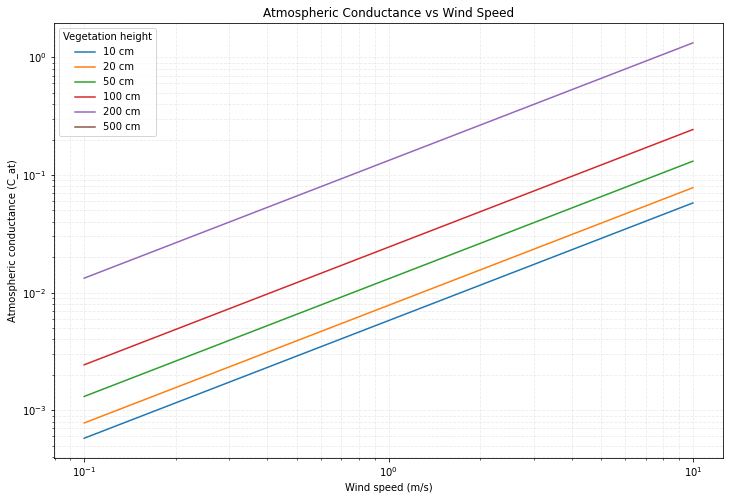

In [8]:
# Q3.2 code here

#So, plot should incorporate different velocities. So different ones are chosen below. 
#Since there is natural logarithm in the formula, creating 100 points between 0.1 and 10 seemed to be an optimal option:
v = np.logspace(-1, 1, 100)   # 0.1 to 10 m/s

heights_cm = [10, 20, 50, 100, 200, 500]
heights_m = [h/100 for h in heights_cm]  # convert cm to meters

plt.figure(figsize=(12,8))

for h_m in heights_m:
    h_cm = h_m * 100
    C = C_at(v, h_m)
    plt.plot(v, C, label=f"{h_cm:.0f} cm")

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Atmospheric conductance (C_at)")
plt.title("Atmospheric Conductance vs Wind Speed")

plt.legend(title="Vegetation height")
plt.grid(True, which="both", linestyle='--', alpha=0.25)

plt.show()

* _The plot shows that atmospheric conductance has positive correlation (the formula also states) with wind speed for all vegetation heights, except for the unplotted highest vegetation height that is unrealistic value. This proportionality is observed because: stronger wind causes more turbulent mixing and removes water vapor from the surface more efficiently, increasing evaporation rates. Moreover, taller vegetation results the higher chance of the atmospheric conductance. Taller vegetation makes the surface rougher, which creates more turbulence and better mixing of air at the ABL. As a result, surfaces with taller vegetation have more efficient vapor transport compared to shorter vegetation. Overall, wind speed mainly controls how fast water vapor can move, while vegetation height changes the overall level of conductance._

### Q4 — Leaf Conductance


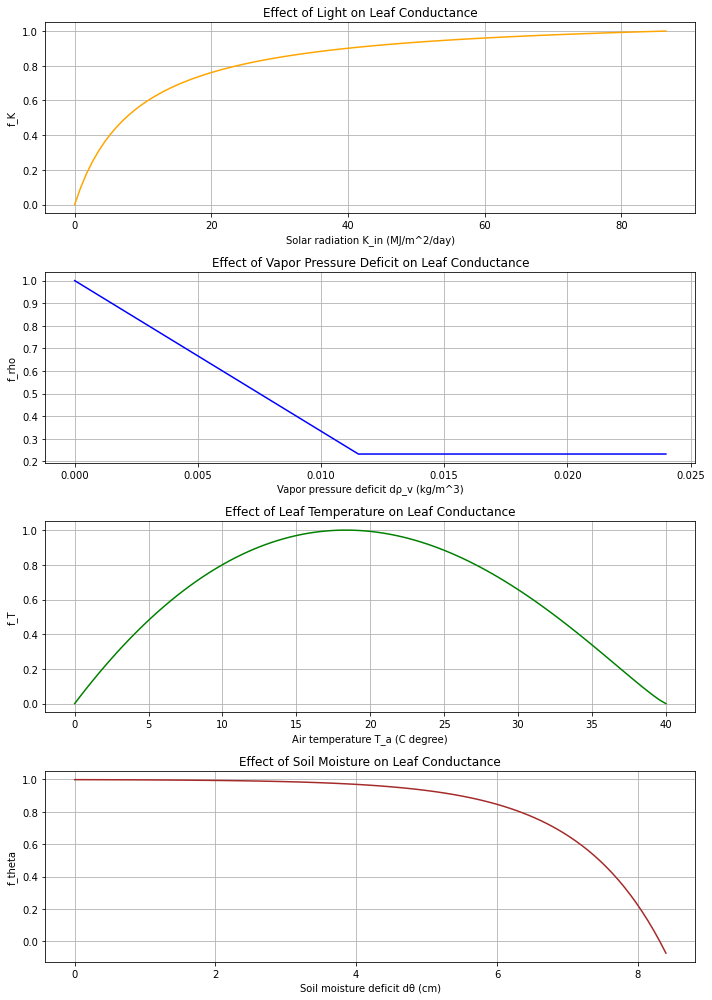

In [11]:
# arrays to use for each function
# note that we have to split up the delta_rho_v array, since the function is piecewise
k_in_arr = np.linspace(0,86.5,100)
delta_rho_v_arr1 = np.linspace(0,0.01152,50)
delta_rho_v_arr2 = np.linspace(0.01152,0.024,50)
T_a_arr = np.linspace(0,40,100)
delta_theta_arr = np.linspace(0,8.4,100)

### your code goes below here ###

#first step is to write all the equations into function form here:


import numpy as np
import matplotlib.pyplot as plt

# Light function
def f_K(K_in):
    return (12.78 * K_in) / (11.57 * K_in + 104.4)

# Vapor pressure deficit
def f_rho(delta_rho_v):
    return np.where(delta_rho_v <= 0.01152, 1 - 66.6 * delta_rho_v, 0.233)

#Leaf temperature function
def f_T(T_a):
    return (T_a * (40 - T_a)**1.18) / 691

# Leaf water content function 
def f_theta(delta_theta):
    return 1 - 0.00119 * np.exp(0.81 * delta_theta)

K_vals = f_K(k_in_arr)
rho_vals = f_rho(np.concatenate([delta_rho_v_arr1, delta_rho_v_arr2]))
T_vals = f_T(T_a_arr)
theta_vals = f_theta(delta_theta_arr)

fig, axs = plt.subplots(4, 1, figsize=(10, 14), sharex=False)

# Light
axs[0].plot(k_in_arr, K_vals, color='orange')
axs[0].set_ylabel("f_K")
axs[0].set_xlabel("Solar radiation K_in (MJ/m^2/day)")
axs[0].set_title("Effect of Light on Leaf Conductance")
axs[0].grid(True)

# Vapor pressure deficit
delta_rho_all = np.concatenate([delta_rho_v_arr1, delta_rho_v_arr2])
axs[1].plot(delta_rho_all, rho_vals, color='blue')
axs[1].set_ylabel("f_rho")
axs[1].set_xlabel("Vapor pressure deficit dρ_v (kg/m^3)")
axs[1].set_title("Effect of Vapor Pressure Deficit on Leaf Conductance")
axs[1].grid(True)

# Leaf temperature
axs[2].plot(T_a_arr, T_vals, color='green')
axs[2].set_ylabel("f_T")
axs[2].set_xlabel("Air temperature T_a (C degree)")
axs[2].set_title("Effect of Leaf Temperature on Leaf Conductance")
axs[2].grid(True)

# Leaf water content
axs[3].plot(delta_theta_arr, theta_vals, color='brown')
axs[3].set_ylabel("f_theta")
axs[3].set_xlabel("Soil moisture deficit dθ (cm)")
axs[3].set_title("Effect of Soil Moisture on Leaf Conductance")
axs[3].grid(True)

plt.tight_layout()
plt.show()

* _The above four functions show how leaf conductance depends on light, vapor pressure deficit, leaf temperature, and soil moisture. Leaf conductance increases with solar radiation but enters plateau at high light magnitudes. It decreases as vapor pressure deficit increases, probably implying to leaf's stomata closure under dry air conditions (to prevent further loss of water as far as I know), and is constant value for very high deficits. Leaf conductance is highest at moderate temperatures and decreases at very low or very high temperatures in a parabolic shape. Finally, it decreases gradually as soil moisture deficit increases, because drier leaves reduce water loss. To calculate transpiration, leaf conductance from these four factors can be combined with atmospheric conductance that was calculated in the Question 3. The two conductances act like resistances, especially the slowest process serving as the control for the total flux. Both conductance can be combined into a new variable in that bulk mass-transfer equation E = Variable_conductance(es-ea)._



### AI Use and Collaboration Disclosure


`<I used ChatGPT to convert yday into proper datetime yy-mm-dd format. To search up certain np functions that were especially useful in the final question, such as np.where, np.concatenate, np.logspace, or pandas function like df.replace.>`